# 02 — Customer segmentation: RFM + K-Means

**Question:** who are our customers, and which groups drive the revenue?

Two complementary methods on the household feature mart (`src/features/household_features.py`, as of day 711):
1. **RFM scoring** — rule-based quintiles and 10 named segments. Transparent, easy to explain to marketing.
2. **K-Means** — groups discovered from behaviour (recency, frequency, monetary, average basket).

Monetary = what the household paid (`customer_paid`, A02). Fuel lines are excluded from basket features (A12).
The same code runs in production: `python -m src.pipelines.segment`.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.features.household_features import build_features, load_inputs
from src.models import segmentation as seg

pd.set_option("display.width", 200)
features = build_features(load_inputs(), as_of_day=711)
features.shape

(2500, 27)

In [2]:
features[["recency", "frequency", "monetary", "avg_basket_value", "trips_per_week", "spend_trend"]].describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
recency,2500.0,25.58,62.79,0.00,1.00,6.00,20.00,657.00
frequency,2500.0,100.63,104.93,1.00,36.00,73.00,129.00,1223.00
monetary,2500.0,3205.94,3330.00,8.17,965.13,2149.11,4392.99,38240.65
avg_basket_value,2500.0,32.13,20.12,2.39,18.02,27.55,41.17,180.43
trips_per_week,2500.0,1.09,1.14,0.01,0.39,0.80,1.40,14.07
spend_trend,2500.0,-0.02,1.61,-7.36,-0.48,0.00,0.51,6.37


## 1. RFM scoring

Each household gets a 1–5 score per dimension (quintiles; recent = 5). Frequency and monetary are combined into one
FM score, and the R × FM grid gives the standard named segments.

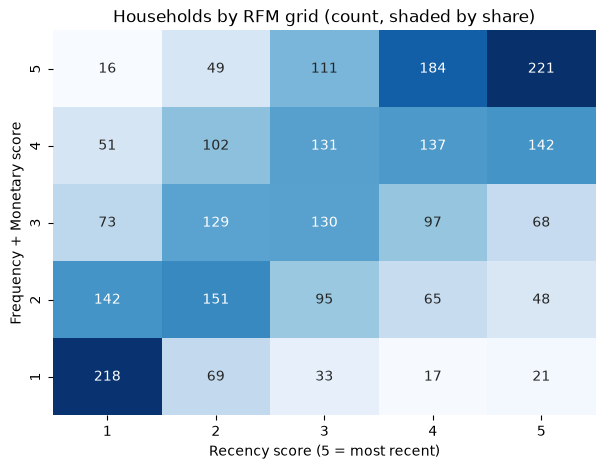

In [3]:
rfm = seg.rfm_scores(features)
grid = rfm.pivot_table(index="fm_score", columns="r_score", values="household_key", aggfunc="count").sort_index(ascending=False)
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(grid / grid.values.sum(), annot=grid, fmt="d", cmap="Blues", cbar=False, ax=ax)
ax.set(title="Households by RFM grid (count, shaded by share)", xlabel="Recency score (5 = most recent)",
       ylabel="Frequency + Monetary score")
plt.show()

In [4]:
rfm_profile = seg.profile(features, rfm.rfm_segment, "rfm_segment")
rfm_profile

,households,recency_median,frequency_median,monetary_median,avg_basket_median,trips_per_week,pct_households,pct_monetary
rfm_segment,,,,,,,,
Can't Lose Them,65,17.0,164.0,5503.860,29.609353,1.752941,0.026,0.048
Champions,363,0.0,156.0,5351.020,29.626351,1.673267,0.145,0.293
Loyal Customers,563,3.0,133.0,4714.620,31.023551,1.452830,0.225,0.390
At Risk,355,19.0,74.0,2339.270,31.228289,0.798438,0.142,0.119
About to Sleep,130,6.0,65.0,1962.150,27.119350,0.698421,0.052,0.032
Potential Loyalist,278,1.0,53.5,1408.835,25.233059,0.597507,0.111,0.054
Need Attention,128,6.0,33.5,874.545,24.510606,0.347521,0.051,0.014
Hibernating,580,38.0,24.5,569.540,23.552204,0.264251,0.232,0.049
Promising,17,3.0,19.0,341.040,16.244000,0.199367,0.007,0.001


## 2. K-Means: choosing k

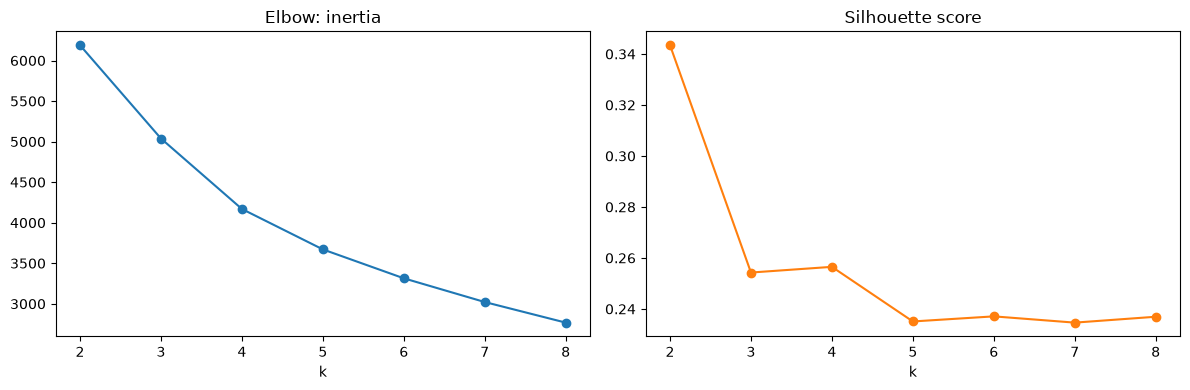

,inertia,silhouette
k,,
2,6188.861,0.343
3,5038.316,0.254
4,4169.261,0.257
5,3670.675,0.235
6,3314.262,0.237
7,3021.601,0.235
8,2767.789,0.237


In [5]:
x, scaler = seg.kmeans_matrix(features)
scores = seg.evaluate_k(x)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
scores.inertia.plot(marker="o", ax=ax[0], title="Elbow: inertia")
scores.silhouette.plot(marker="o", ax=ax[1], title="Silhouette score", color="tab:orange")
plt.tight_layout(); plt.show()
scores.round(3)

**Decision: k = 4.** k = 2 has the highest silhouette (0.34) but only splits active from inactive, which adds nothing
to RFM. Among k = 3–8, k = 4 has the best silhouette (≈0.26) and the elbow flattens after it; its four groups are also
clearly different and actionable. Silhouette ≈ 0.26 means the groups overlap: customer behaviour is a continuum, so
segments are a useful simplification, not natural species.

In [6]:
km = seg.fit_kmeans(x, 4)
features["segment"] = seg.name_clusters(features, km.labels_).values
cluster_profile = seg.profile(features, features.segment, "segment")
cluster_profile

,households,recency_median,frequency_median,monetary_median,avg_basket_median,trips_per_week,pct_households,pct_monetary
segment,,,,,,,,
VIP Regulars,771,2.0,138.0,5689.60,35.326346,1.504950,0.308,0.648
Occasional Stock-Up Shoppers,683,16.0,46.0,1860.02,39.194706,0.507087,0.273,0.188
Frequent Top-Up Shoppers,630,3.0,93.5,1714.21,16.565395,1.013236,0.252,0.144
Lapsing Low-Value,416,47.5,18.0,340.69,17.759857,0.198333,0.166,0.020


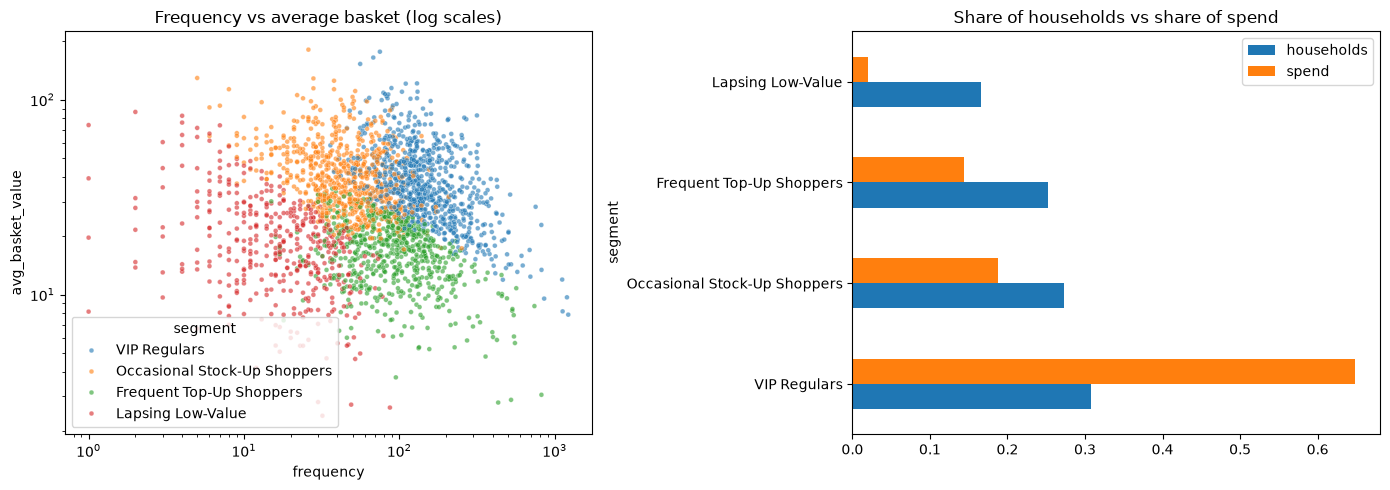

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=features, x="frequency", y="avg_basket_value", hue="segment", s=12, alpha=0.6, ax=ax[0])
ax[0].set(xscale="log", yscale="log", title="Frequency vs average basket (log scales)")
share = cluster_profile[["pct_households", "pct_monetary"]].rename(columns={"pct_households": "households",
                                                                             "pct_monetary": "spend"})
share.plot.barh(ax=ax[1], title="Share of households vs share of spend")
plt.tight_layout(); plt.show()

## 3. Do the two methods agree?

In [8]:
pd.crosstab(rfm.rfm_segment, features.segment)

segment,Frequent Top-Up Shoppers,Lapsing Low-Value,Occasional Stock-Up Shoppers,VIP Regulars
rfm_segment,,,,
About to Sleep,62,0,67,1
At Risk,84,6,254,11
Can't Lose Them,15,0,15,35
Champions,78,0,0,285
Hibernating,26,358,196,0
Loyal Customers,142,0,27,394
Need Attention,31,37,60,0
New Customers,11,5,5,0
Potential Loyalist,176,0,57,45


## 4. Segments × marketing behaviour

In [9]:
mkt = features.groupby("segment").agg(
    households=("household_key", "size"),
    received_campaign=("campaigns_received", lambda s: (s > 0).mean()),
    redeemed_coupon=("redeemed_any", "mean"),
    private_label_share=("private_label_share", "median"),
    loyalty_savings_rate=("loyalty_savings_rate", "median"),
    spend_trend_median=("spend_trend", "median"),
    fuel_buyers=("fuel_spend", lambda s: (s > 0).mean()),
).round(3)
mkt

,households,received_campaign,redeemed_coupon,private_label_share,loyalty_savings_rate,spend_trend_median,fuel_buyers
segment,,,,,,,
Frequent Top-Up Shoppers,630,0.684,0.094,0.239,0.151,0.083,0.733
Lapsing Low-Value,416,0.070,0.000,0.215,0.148,0.000,0.392
Occasional Stock-Up Shoppers,683,0.561,0.091,0.208,0.154,0.000,0.738
VIP Regulars,771,0.961,0.406,0.203,0.141,-0.025,0.943


## 5. Findings and recommended actions

Numbers refer to the outputs above (as of day 711).

| Segment | Who they are | Value | Suggested action |
|---|---|---|---|
| **VIP Regulars** | ~31% of households, shop ~1.5×/week, last trip ~2 days ago, ~$35 baskets | **~65% of spend** | Protect: loyalty perks, early access, monitor for any drop in frequency (churn model, Phase 4) |
| **Occasional Stock-Up Shoppers** | ~27%, big baskets (~$39) but only ~0.5 trips/week, recency ~16 days | ~19% | Grow frequency: mid-week reminders, campaigns between big shops |
| **Frequent Top-Up Shoppers** | ~25%, ~1 trip/week but small baskets (~$17) | ~14% | Grow basket size: cross-sell, bundles, category coupons |
| **Lapsing Low-Value** | ~17%, last trip ~48 days ago, ~18 baskets in two years | ~2% | Low-cost win-back only; don't overspend |

- Spend is concentrated: VIP Regulars plus Stock-Up Shoppers (~58% of households) bring ~84% of spend.
- RFM and K-Means agree on the extremes (Champions ⊂ VIP, Hibernating ⊂ Lapsing). K-Means adds what RFM can't see:
  it separates *how* people shop (many small trips vs few big ones) at similar total spend.
- Campaign targeting already follows value (see section 4): heavier segments received more campaigns and redeem more,
  which means campaign effects cannot be read from raw redemption rates (selection bias — relevant for Phase 4).